c:\Users\Pc\Documents\tess-transit-project\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 18 data products.

 #      mission     year author exptime target_name distance
                                   s                 arcsec 
--- --------------- ---- ------ ------- ----------- --------
  0  TESS Sector 02 2018   SPOC     120   100100827      0.0
  1  TESS Sector 03 2018   SPOC     120   100100827      0.0
  2  TESS Sector 29 2020   SPOC      20   100100827      0.0
  3  TESS Sector 30 2020   SPOC      20   100100827      0.0
  4  TESS Sector 29 2020   SPOC     120   100100827      0.0
  5  TESS Sector 30 2020   SPOC     120   100100827      0.0
  6  TESS Sector 69 2023   SPOC      20   100100827      0.0
  7  TESS Sector 69 2023   SPOC     120   100100827      0.0
  8  TESS Sector 96 2025   SPOC      20   100100827      0.0
  9  TESS Sector 96 2025   SPOC     120   100100827      0.0
 10 TESS Sector 103 2026   SPOC      20   100100827      0.0
 11 TESS Sector 104 2026   SPOC      20   100100827      0.0
 12 TESS Sector 105 2026   SPOC      20   

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

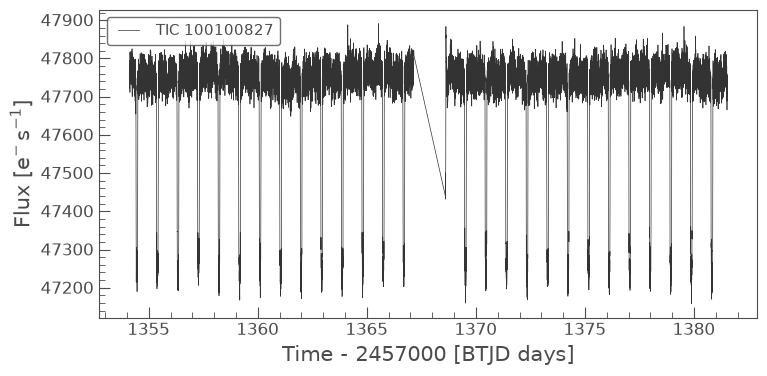

In [1]:
import lightkurve as lk

search = lk.search_lightcurve("WASP-18", mission="TESS", author="SPOC")
print(search)

lc = search[0].download()
lc.plot()

In [2]:
# Καθαρισμός: αφαιρούμε κενές τιμές και κάνουμε τη φωτεινότητα σχετική (μέσος όρος = 1)
lc_clean = lc.remove_nans().normalize()

# Αφαιρούμε τις αργές μεταβολές του άστρου, κρατώντας τις γρήγορες βυθίσεις
lc_flat = lc_clean.flatten(window_length=901)
lc_flat.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

In [3]:
import numpy as np

# Ψάχνουμε περιόδους από 0,5 έως 3 μέρες με τη μέθοδο BLS (Box Least Squares)
periods = np.linspace(0.5, 3, 10000)
bls = lc_flat.to_periodogram(method="bls", period=periods)
bls.plot()

period = bls.period_at_max_power
t0 = bls.transit_time_at_max_power
duration = bls.duration_at_max_power
print("Περίοδος:", period)
print("Χρόνος διάβασης:", t0)
print("Διάρκεια:", duration)

# "Διπλώνουμε" την καμπύλη πάνω στην περίοδο
lc_flat.fold(period=period, epoch_time=t0).scatter()

Περίοδος: 0.9415441544154415 d
Χρόνος διάβασης: 1354.4515072617191
Διάρκεια: 0.1 d


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

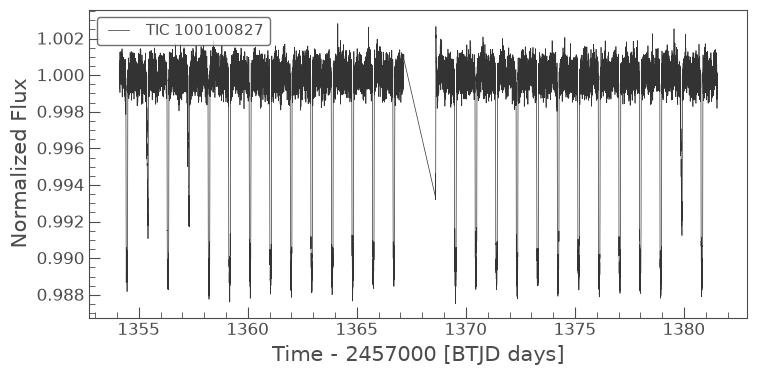

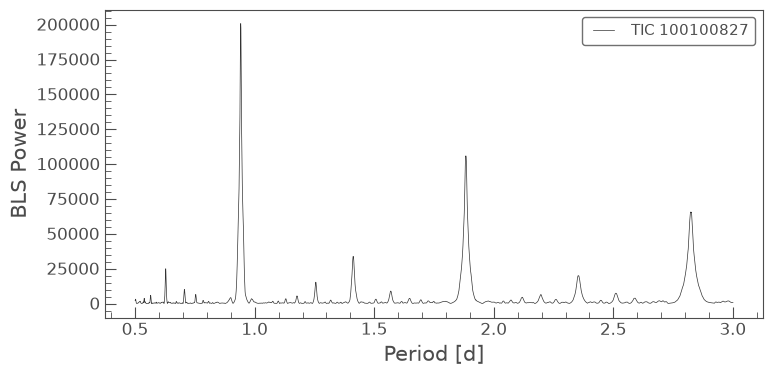

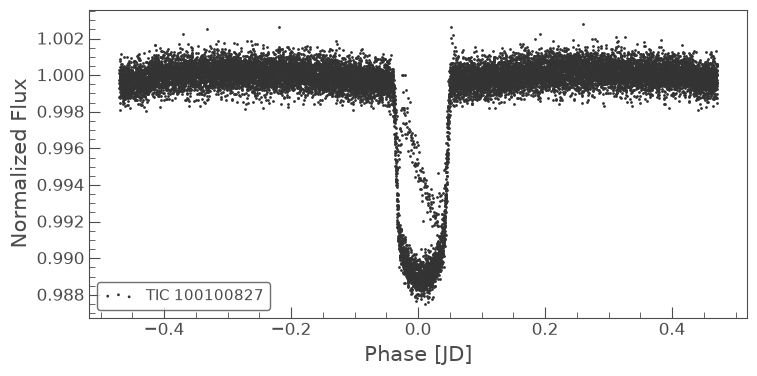

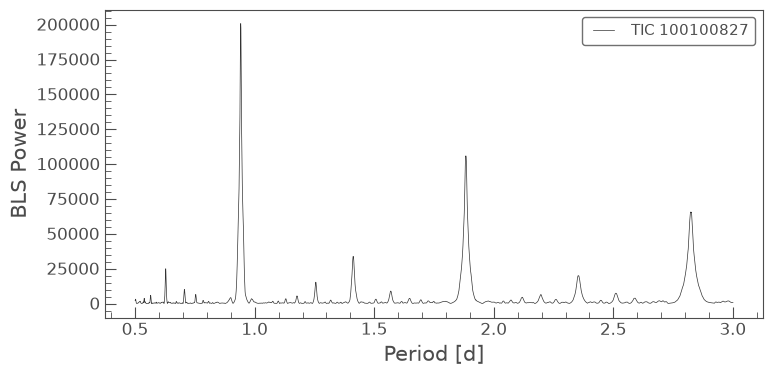

In [4]:
import matplotlib.pyplot as plt
bls.plot()
plt.show()

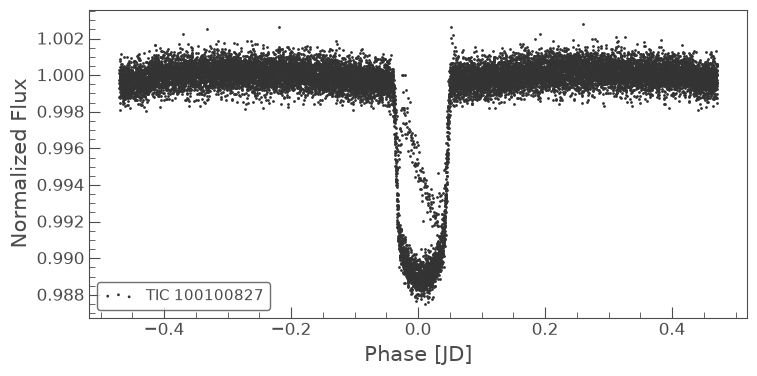

In [5]:
import matplotlib.pyplot as plt
lc_flat.fold(period=period, epoch_time=t0).scatter()
plt.show()

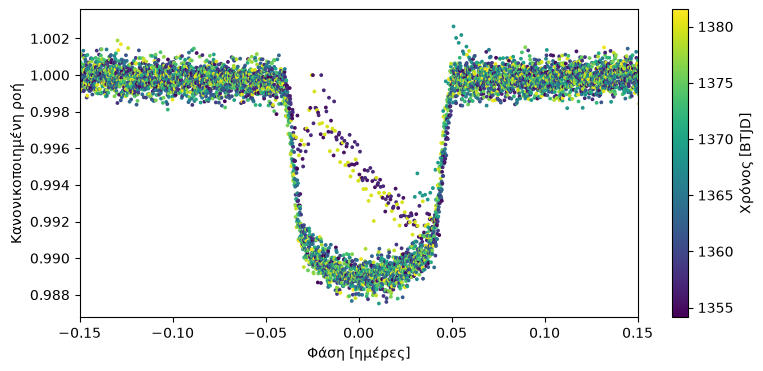

In [6]:
import matplotlib.pyplot as plt
folded = lc_flat.fold(period=period, epoch_time=t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded.time.value, folded.flux.value,
                 c=folded.time_original.value, s=3, cmap="viridis")
plt.colorbar(sc, label="Χρόνος [BTJD]")
plt.xlim(-0.15, 0.15)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.show()

In [7]:
import matplotlib.pyplot as plt

# σημάδεψε τα σημεία μέσα στις διαβάσεις (με λίγο περιθώριο)
transit_mask = lc_clean.create_transit_mask(period=period, transit_time=t0, duration=0.15)

# ίσιωσε την καμπύλη αγνοώντας αυτά τα σημεία
lc_flat2 = lc_clean.flatten(window_length=901, mask=transit_mask)

folded2 = lc_flat2.fold(period=period, epoch_time=t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded2.time.value, folded2.flux.value,
                 c=folded2.time_original.value, s=3, cmap="viridis")
plt.colorbar(sc, label="Χρόνος [BTJD]")
plt.xlim(-0.15, 0.15)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.show()

TypeError: cannot write to unmasked output

Σημεία μέσα σε διάβαση: 2884 από 18299


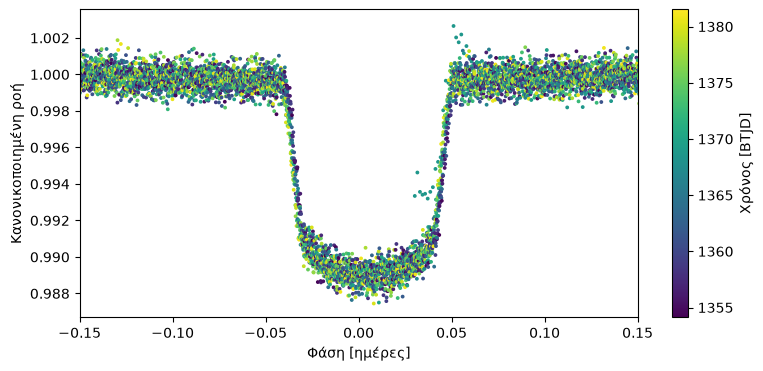

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# απλοί αριθμοί αντί για "masked" πίνακες
t = lc_clean.time.value
t = np.asarray(getattr(t, "unmasked", t), dtype=float)
P = float(period.value)    # περίοδος σε ημέρες
T0 = float(t0.value)       # χρόνος διάβασης σε BTJD
dur = 0.15                 # πλάτος μάσκας σε ημέρες (η διάβαση κρατά ~0,09)

# True για τα σημεία μέσα σε διάβαση
transit_mask = np.abs((t - T0 + P/2) % P - P/2) < dur/2
print("Σημεία μέσα σε διάβαση:", transit_mask.sum(), "από", len(t))

# ίσιωσε την καμπύλη αγνοώντας αυτά τα σημεία
lc_flat2 = lc_clean.flatten(window_length=901, mask=transit_mask)

folded2 = lc_flat2.fold(period=period, epoch_time=t0)
plt.figure(figsize=(9, 4))
sc = plt.scatter(folded2.time.value, folded2.flux.value,
                 c=folded2.time_original.value, s=3, cmap="viridis")
plt.colorbar(sc, label="Χρόνος [BTJD]")
plt.xlim(-0.15, 0.15)
plt.xlabel("Φάση [ημέρες]")
plt.ylabel("Κανονικοποιημένη ροή")
plt.show()